In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from metrics import mae, coverage, avg_width

preds = pd.read_csv("../results/backtest_predictions.csv", index_col=0, parse_dates=True)
df = pd.read_csv("../data/clean_hourly.csv", index_col=0, parse_dates=True)

# add the holiday / weather / temperature columns to our predictions
data = preds.join(df[["holiday", "weathersit", "temp"]])
print(data.shape)

(8784, 9)


In [2]:
daily = data["cnt"].resample("D").sum()
print(daily.sort_values().head(8))

datetime
2012-10-29      22.0
2012-12-26     441.0
2012-12-24     920.0
2012-12-25    1013.0
2012-04-22    1027.0
2012-10-30    1096.0
2012-01-21    1301.0
2012-12-29    1341.0
Name: cnt, dtype: float64


In [3]:
data["is_holiday"] = data["holiday"] == 1
data["bad_weather"] = data["weathersit"] >= 3

# extreme temperature = the coldest 5% or hottest 5% of hours
cold = data["temp"].quantile(0.05)
hot = data["temp"].quantile(0.95)
data["extreme_temp"] = (data["temp"] <= cold) | (data["temp"] >= hot)

# storm days
data["is_storm"] = (data.index >= "2012-10-29") & (data.index < "2012-10-31")

# anything unusual
data["unusual"] = (
    data["is_holiday"] | data["bad_weather"] | data["extreme_temp"] | data["is_storm"]
)

print(data[["is_holiday", "bad_weather", "extreme_temp", "is_storm", "unusual"]].sum())

is_holiday       264
bad_weather      678
extreme_temp    1053
is_storm          48
unusual         1889
dtype: int64


In [4]:
def summarize(name, d):
    return {
        "group": name,
        "hours": len(d),
        "MAE": mae(d["cnt"], d["median"]),
        "coverage_raw": coverage(d["cnt"], d["lower_raw"], d["upper_raw"]),
        "coverage_cal": coverage(d["cnt"], d["lower_cal"], d["upper_cal"]),
        "avg_width_cal": avg_width(d["lower_cal"], d["upper_cal"]),
    }

In [5]:
rows = []
rows.append(summarize("normal hours", data[~data["unusual"]]))
rows.append(summarize("holidays", data[data["is_holiday"]]))
rows.append(summarize("bad weather", data[data["bad_weather"]]))
rows.append(summarize("extreme temperature", data[data["extreme_temp"]]))
rows.append(summarize("storm days", data[data["is_storm"]]))
rows.append(summarize("all unusual", data[data["unusual"]]))

unusual_results = pd.DataFrame(rows)
print(unusual_results)
unusual_results.to_csv("../results/unusual_period_results.csv", index=False)

                 group  hours        MAE  coverage_raw  coverage_cal  \
0         normal hours   6895  51.696126      0.836838      0.876142   
1             holidays    264  78.618456      0.753788      0.806818   
2          bad weather    678  65.940554      0.774336      0.846608   
3  extreme temperature   1053  52.728487      0.831909      0.883191   
4           storm days     48  81.442960      0.291667      0.416667   
5          all unusual   1889  60.227005      0.805717      0.863949   

   avg_width_cal  
0     235.021821  
1     258.165035  
2     258.941916  
3     267.351828  
4     290.606374  
5     264.608180  


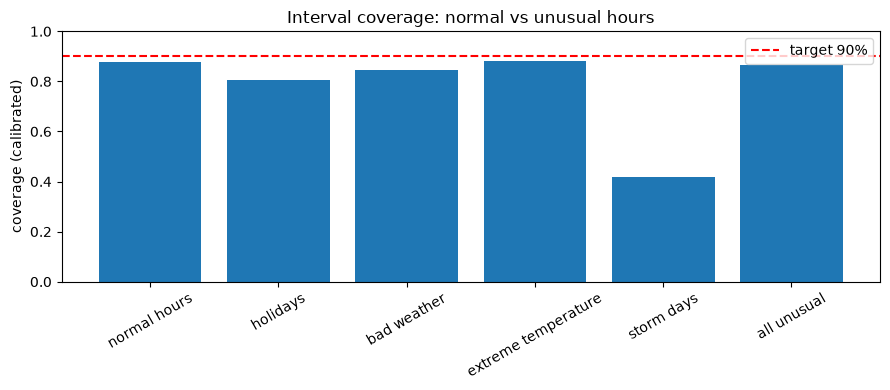

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(unusual_results["group"], unusual_results["coverage_cal"])
plt.axhline(0.9, color="red", linestyle="--", label="target 90%")
plt.xticks(rotation=30)
plt.ylabel("coverage (calibrated)")
plt.title("Interval coverage: normal vs unusual hours")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig("../results/unusual_coverage.png")
plt.show()

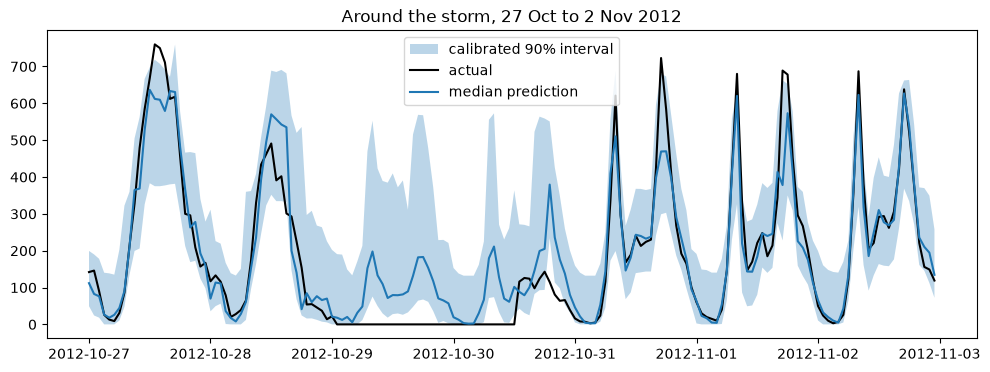

In [7]:
storm = data.loc["2012-10-27":"2012-11-02"]

plt.figure(figsize=(12, 4))
plt.fill_between(storm.index, storm["lower_cal"], storm["upper_cal"], alpha=0.3, label="calibrated 90% interval")
plt.plot(storm["cnt"], color="black", label="actual")
plt.plot(storm["median"], label="median prediction")
plt.legend()
plt.title("Around the storm, 27 Oct to 2 Nov 2012")
plt.savefig("../results/storm_week.png")
plt.show()

In [8]:
data["inside_cal"] = (data["cnt"] >= data["lower_cal"]) & (data["cnt"] <= data["upper_cal"])
print(data["inside_cal"].loc["2012-10-27":"2012-11-02"].resample("D").mean())

datetime
2012-10-27    0.875000
2012-10-28    0.958333
2012-10-29    0.250000
2012-10-30    0.583333
2012-10-31    0.958333
2012-11-01    0.875000
2012-11-02    0.958333
Freq: D, Name: inside_cal, dtype: float64


In [ ]:
0